# 04 - Sentiment Analysis and NLP

**Topics:** VADER and TextBlob sentiment → positive / negative / neutral → compare with customer ratings → n-grams → TF-IDF → important words and phrases.

**Concept first - what is sentiment analysis, and why do we need it when we already have stars?**
Stars are one number the customer chose. Text carries the *reasons*. Sentiment analysis converts text to a score so we can (a) analyse the 0.4% of reviews with no rating, (b) detect reviews where text and stars disagree, and (c) measure sentiment per topic (e.g. Delivery complaints vs Pricing complaints), which stars cannot do.

| Tool | How it works | Strength | Weakness |
|---|---|---|---|
| **VADER** | lexicon + rules (punctuation, CAPS, emojis, negation, "but") | built for short informal reviews | adds up words; blind to long mixed reviews |
| **TextBlob** | pattern lexicon of adjectives (polarity & subjectivity) | gives subjectivity too | weaker on negation & slang |

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import re
import pandas as pd
import numpy as np
from IPython.display import display, Image
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)
from run_pipeline import build_dataset
df, meta, log = build_dataset()
print("Rows:", len(df), "| Columns:", df.shape[1])
print(log)

Rows: 9944 | Columns: 49
{'raw_rows': 10000, 'after_drop_empty_rows': 9962, 'non_numeric_ratings': 1, 'after_drop_empty_text': 9944, 'repeat_reviewer_text_kept': 6}


## 1. Try the tools on examples before trusting them
Important design choice: **VADER gets the raw review** (it needs `!!!`, `CAPS`, emojis), while **TF-IDF / n-grams get the cleaned text**.

In [2]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
sia = SentimentIntensityAnalyzer()
samples = ["The food was good", "The food was NOT good", "AMAZING food!!! 😍", "Food was good but the service was terrible",
           "Wow, great, an hour late again. Thanks a lot.", "ok", "Worst biryani ever, never coming back"]
rows = [{"text": t, "VADER": sia.polarity_scores(t)["compound"], "TextBlob": round(TextBlob(t).sentiment.polarity, 2)} for t in samples]
pd.DataFrame(rows)

,text,VADER,TextBlob
0,The food was good,0.4404,0.70
1,The food was NOT good,-0.3412,-0.35
2,AMAZING food!!! 😍,0.8559,1.00
3,Food was good but the service was terrible,-0.4939,-0.15
4,"Wow, great, an hour late again. Thanks a lot.",0.8957,0.20
5,ok,0.2960,0.50
6,"Worst biryani ever, never coming back",-0.6249,-0.50


Observations: both handle plain negation ("NOT good"); **sarcasm** ("great, an hour late again") is the classic miss; mixed sentences land near the middle. Standard VADER thresholds: `>= 0.05` positive, `<= -0.05` negative, otherwise neutral.

## 2. Sentiment on all reviews

In [3]:
print("VADER label distribution (%):"); print((df.vader_label.value_counts(normalize=True)*100).round(1).to_string())
print("\nTextBlob label distribution (%):"); print((df.textblob_label.value_counts(normalize=True)*100).round(1).to_string())
print("\nStar-based label distribution (%):"); print((df.rating_sentiment.value_counts(normalize=True)*100).round(1).to_string())

VADER label distribution (%):
vader_label
Positive    74.3
Negative    18.6
Neutral      7.1

TextBlob label distribution (%):
textblob_label
Positive    72.1
Negative    17.4
Neutral     10.6

Star-based label distribution (%):
rating_sentiment
Positive    62.9
Negative    24.4
Neutral     12.6


## 3. Compare sentiment with customer ratings
Star-based label: 1-2 = Negative, 3 = Neutral, 4-5 = Positive.

In [4]:
from src.sentiment_nlp import agreement_table, agreement_metrics
ct = agreement_table(df)
display(ct)
display(agreement_metrics(df))

vader_label,Negative,Neutral,Positive
rating_sentiment,,,
Negative,1551,294,582
Neutral,222,128,907
Positive,74,288,5897


,engine,exact_agreement_%,polarity_agreement_%,spearman_vs_rating,pearson_vs_rating
0,VADER,76.2,91.9,0.583,0.714
1,TextBlob,74.1,91.7,0.677,0.695


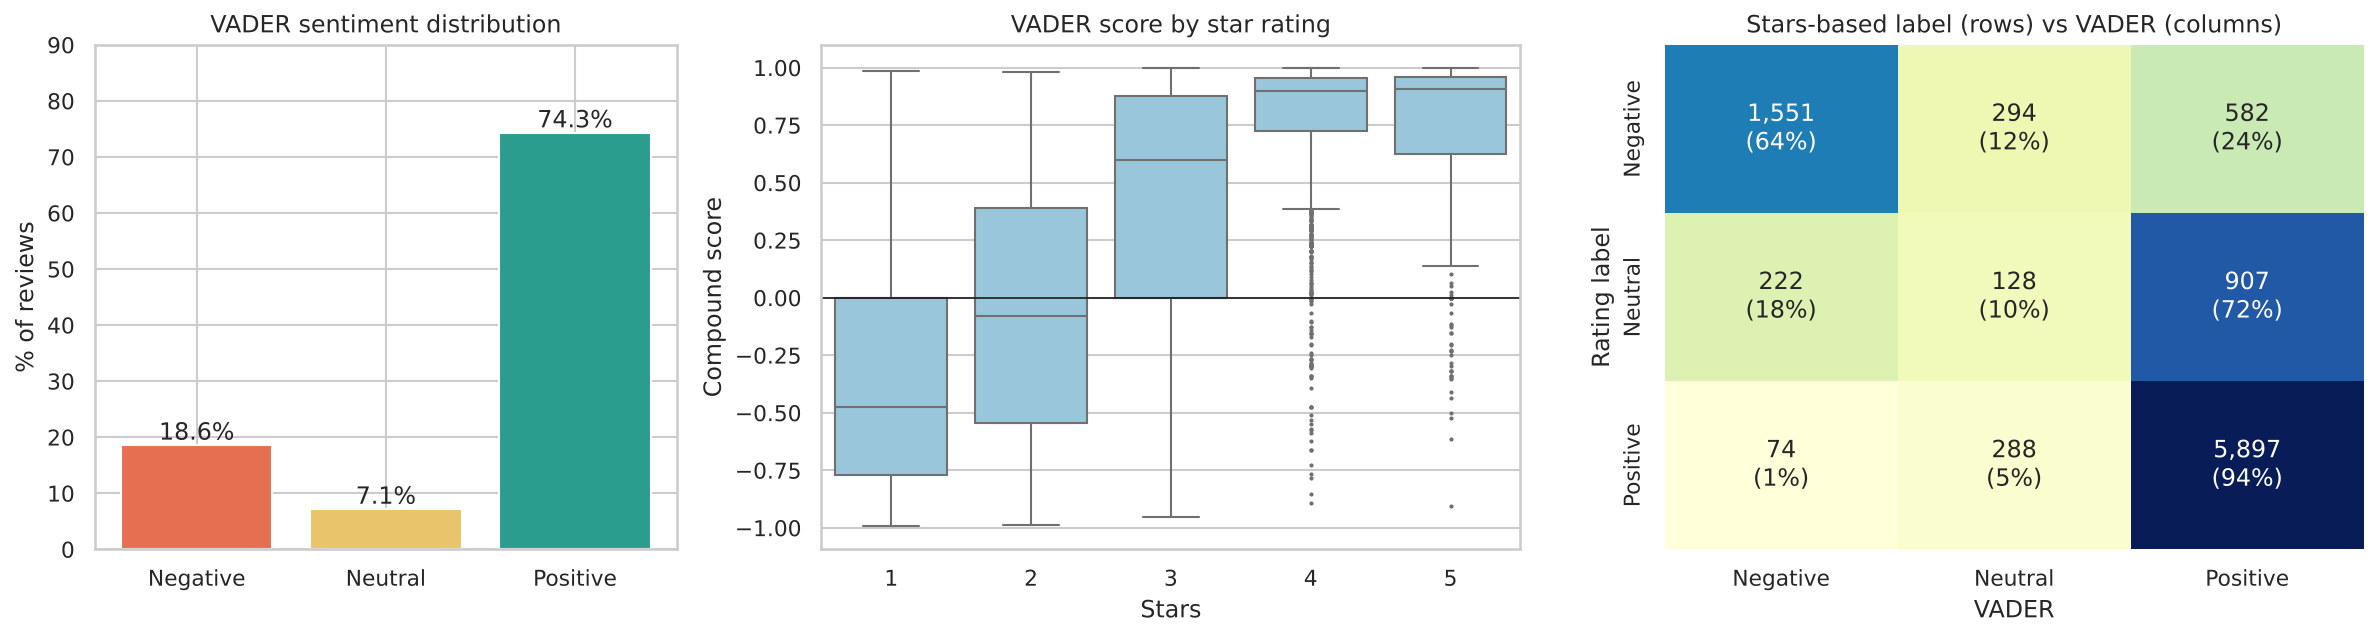

In [5]:
Image("../outputs/figures/04_sentiment_vs_rating.png")

**Reading the matrix**
* When both sources take a side (ignoring neutral), VADER and the stars agree **~92%** of the time.
* The weak spot is **3-star reviews: 72% of them read as positive text.** A 3-star is usually "good, but...". Stars carry the *dealbreaker*, text carries the praise.
* A quarter of 1-2★ reviews are positive by VADER - investigated next.

In [6]:
from src.sentiment_nlp import flag_mismatches
print(df.mismatch_type.value_counts().to_string())
pd.set_option("display.max_colwidth", 330)
df[df.mismatch_type=="Low stars, positive text"][["Rating","vader_compound","Review"]].sample(4, random_state=8)

mismatch_type
Consistent                   9615
Low stars, positive text      295
High stars, negative text      34


,Rating,vader_compound,Review
7895,2,0.5857,"I went for dinner with my friends. The food is good. We ordered chicken manchow soup, apolo fish as starters and alfredo pasta as the main course.\nButt we found a cockroach on the table while we were having our dinner.\n\nSo, 2 star as it really freaked me out!"
5490,1,0.8490,"I just got a rice meal box which included ginger paneer on the side. And the following were my observations:-\n1) the rice was semi cooked, it was not even boiled properly.\n2) the paneer portion was absolutely insufficient to complement the quantity of rice.\n3) the paneer tasted disgusting and it was absolutely dry though ..."
3331,1,0.7185,"I went to club rouge since the day it started,I have been to this place more than 150 times.It was like a hangout place for us to always go.It was beautiful in the starting,less crowd and only couples were allowed to dance floors and people dint stand on tables and all that time to dance.Bouncers were pretty good at that tim..."
4343,2,0.9401,Kindly try putting more stuffing in the waffles.. we ordered two but it was all bread hence couldn't eat any. Ice cream waffle was all melted.. kindly remove it from online if we are unable to deliver with dry ice. Banana caramel waffle was all dry.. expecting better qualities for the next order. Thanks a lot!!


These are long, mixed reviews: praise for ambience/food dominates the text, one dealbreaker (slow staff, delay, rude behaviour, wrong order) decides the stars. That is exactly why **complaint categories add value on top of sentiment** - VADER alone would file these as happy customers.

Compound score by *complaint category* - which complaints actually sound angry?

In [7]:
pd.set_option("display.max_colwidth", 140)
from src.complaints import CATEGORY_COLUMNS
rows = []
for cat, col in CATEGORY_COLUMNS.items():
    s = df[df[col]==1]
    rows.append({"category": cat, "reviews": len(s), "avg_vader": round(s.vader_compound.mean(),3),
                 "% negative text": round((s.vader_label=="Negative").mean()*100,1), "avg stars": round(s.Rating_numeric.mean(),2)})
pd.DataFrame(rows).sort_values("avg_vader")

,category,reviews,avg_vader,% negative text,avg stars
5,Hygiene,200,-0.223,65.0,1.66
0,Delivery,243,-0.129,50.6,1.72
2,Packaging,40,-0.102,55.0,2.25
1,Food Quality,1648,-0.028,51.4,2.06
4,Staff & Service,967,0.016,49.0,2.18
3,Pricing,674,0.248,32.8,2.82


Hygiene and Delivery complaints read the angriest. **Pricing and Staff complaints are written in a *polite* tone** (VADER is near/above zero: "a bit expensive but...") even though they cost ~1 star - they would be underweighted by a sentiment-only dashboard.

## 4. N-grams
A unigram is one word; a bigram is two consecutive words. Why bother? Single words lose context: `good` appears in *both* happy ("very good") and unhappy ("not good") reviews. Bigrams recover that. Stop-words are removed **except negations** (`not`, `no`, `never`), which carry meaning.

In [8]:
from src.sentiment_nlp import top_ngrams, ngrams_by_group
neg_txt = df.loc[df.rating_sentiment=="Negative","Review_clean"]
pos_txt = df.loc[df.rating_sentiment=="Positive","Review_clean"]
bi = pd.concat([top_ngrams(neg_txt,(2,2),12).add_prefix("neg_"), top_ngrams(pos_txt,(2,2),12).add_prefix("pos_")], axis=1)
bi

,neg_ngram,neg_count,pos_ngram,pos_count
0,not good,270,food good,416
1,did not,267,good food,388
2,food not,146,main course,313
3,main course,97,good service,280
4,bad experience,89,service good,251
5,worst experience,87,ambience good,211
6,not worth,86,non veg,204
7,does not,83,ice cream,199
8,waste money,73,did not,192
9,ice cream,71,food service,171


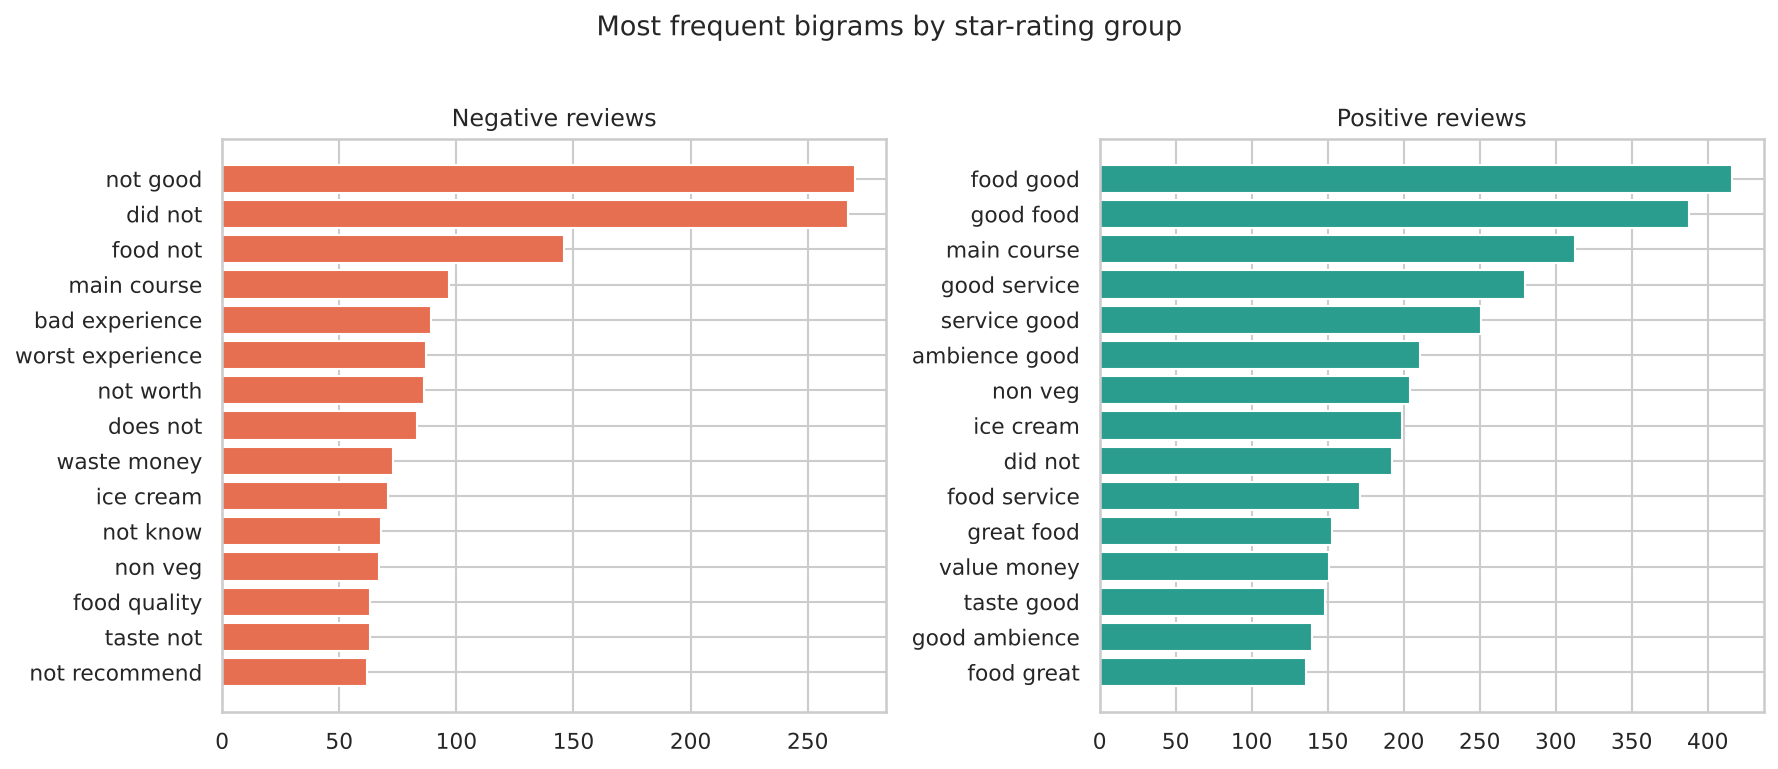

In [9]:
Image("../outputs/figures/05a_bigrams.png")

In [10]:
print("Trigrams"); display(pd.read_csv("../outputs/tables/trigrams.csv").pivot_table(index=pd.read_csv("../outputs/tables/trigrams.csv").groupby("rating_sentiment").cumcount(), columns="rating_sentiment", values="ngram", aggfunc="first"))

Trigrams


rating_sentiment,Negative,Positive
0,food not good,veg non veg
1,taste not good,north indian food
2,veg non veg,overall good experience
3,not upto mark,food good service
4,not worth money,good food good
5,quality not good,good service good
6,food not great,starters main course
7,did not taste,food ambience service
8,not cooked properly,paneer butter masala
9,not good experience,ambience good food


Negative reviews are dominated by `not good`, `bad experience`, `worst experience`, `not worth`, `waste money`, `not recommend`; the trigrams add `food not good`, `taste not good`, `not upto mark`, `not worth money`. Positive reviews: `good food`, `good service`, `ambience good`, `great food`, `value money`. The two lists overlap mainly on *menu* words (`main course`, `ice cream`, `non veg`) - the opinion vocabulary is clearly separated, which is why simple models work well here.

## 5. TF-IDF - which words are *important*, not just frequent?
**Term Frequency × Inverse Document Frequency.** A word scores high when it is frequent in a review but rare across all reviews. Counting alone ranks `food` first everywhere; TF-IDF down-weights words every review uses and highlights the distinctive ones.

Tiny demo first, to see the mechanics:

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
toy = ["food was good", "food was cold and slow", "slow delivery and cold food"]
v = TfidfVectorizer(); X = v.fit_transform(toy)
pd.DataFrame(X.toarray().round(2), columns=v.get_feature_names_out(), index=["doc1","doc2","doc3"])

,and,cold,delivery,food,good,slow,was
doc1,0.00,0.00,0.00,0.43,0.72,0.00,0.55
doc2,0.47,0.47,0.00,0.36,0.00,0.47,0.47
doc3,0.43,0.43,0.57,0.34,0.00,0.43,0.00


`food` is in every document, so it gets a low weight; `delivery`, `good`, `slow` identify individual documents. On the real data (mean TF-IDF per rating group, sub-linear TF, min_df=5, 1-2 grams):

In [12]:
tf = pd.read_csv("../outputs/tables/tfidf_top_terms.csv")
tf.assign(rank=tf.groupby("rating_sentiment").cumcount()+1).pivot(index="rank", columns="rating_sentiment", values="term")

rating_sentiment,Negative,Positive
rank,,
1,not,good
2,worst,food
3,food,nice
4,bad,service
5,no,great
6,not good,awesome
7,chicken,ambience
8,good,best
9,taste,time


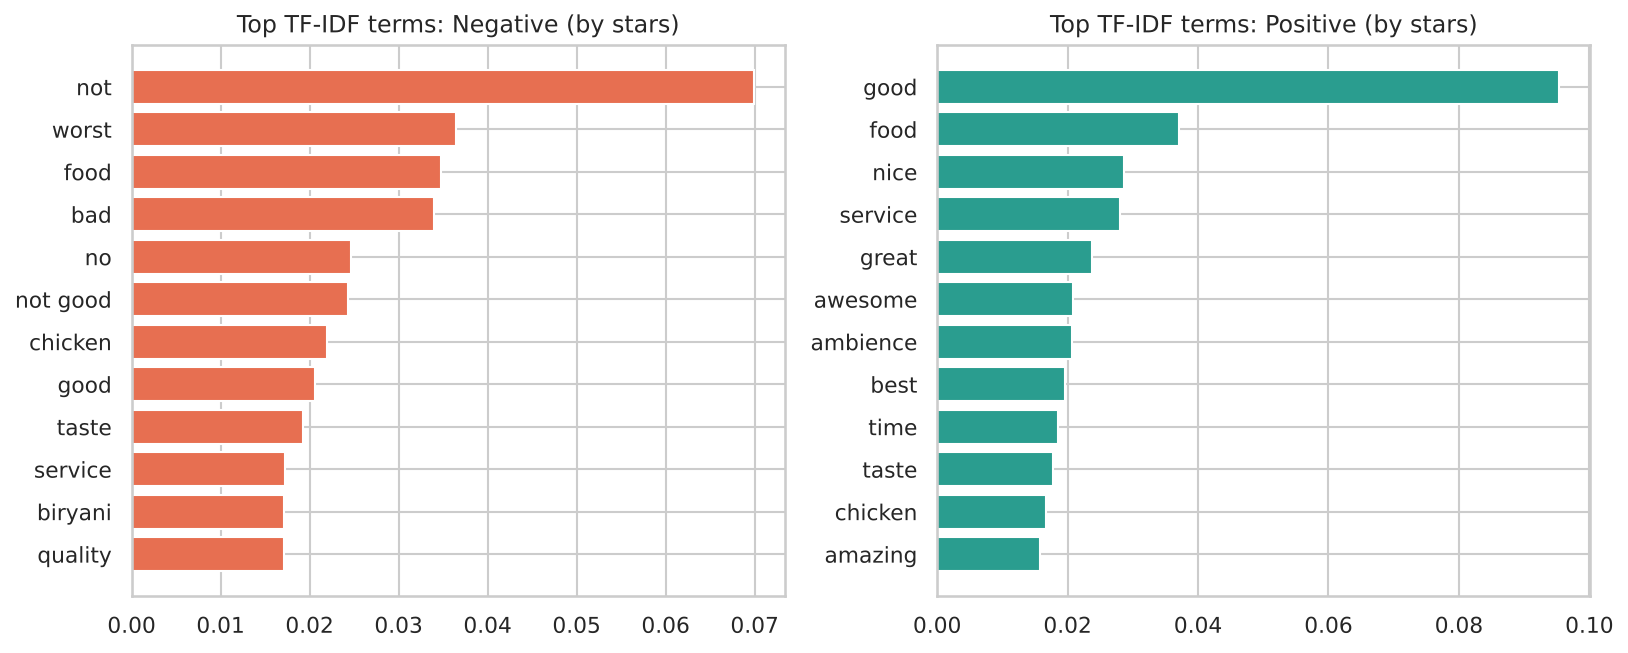

In [13]:
Image("../outputs/figures/05_tfidf_terms.png")

## 6. Which words predict a bad rating? (TF-IDF + logistic regression)
Use the stars as free labels (1-2★ = negative, 4-5★ = positive, 3★ dropped as ambiguous), train on 80%, test on 20%. The model coefficients are an interpretable ranking of "important words".

In [14]:
from src.sentiment_nlp import train_word_importance
metrics, neg_words, pos_words = train_word_importance(df)
print(metrics)
display(pd.concat([neg_words.head(15).add_prefix("neg_"), pos_words.head(15).add_prefix("pos_")], axis=1))

{'auc': 0.989, 'accuracy': 0.959, 'negative_f1': 0.926, 'negative_recall': 0.93, 'negative_precision': 0.922, 'n_train': 6948, 'n_test': 1738}


,neg_term,neg_coef,pos_term,pos_coef
0,not,10.364,good,-6.867
1,worst,7.533,best,-6.345
2,bad,6.434,great,-5.592
3,no,4.671,awesome,-5.411
4,pathetic,4.658,amazing,-5.125
5,not good,4.089,nice,-4.858
6,disappointed,3.453,try,-4.557
7,poor,3.451,loved,-4.191
8,waste,3.183,delicious,-4.166
9,horrible,3.088,love,-4.062


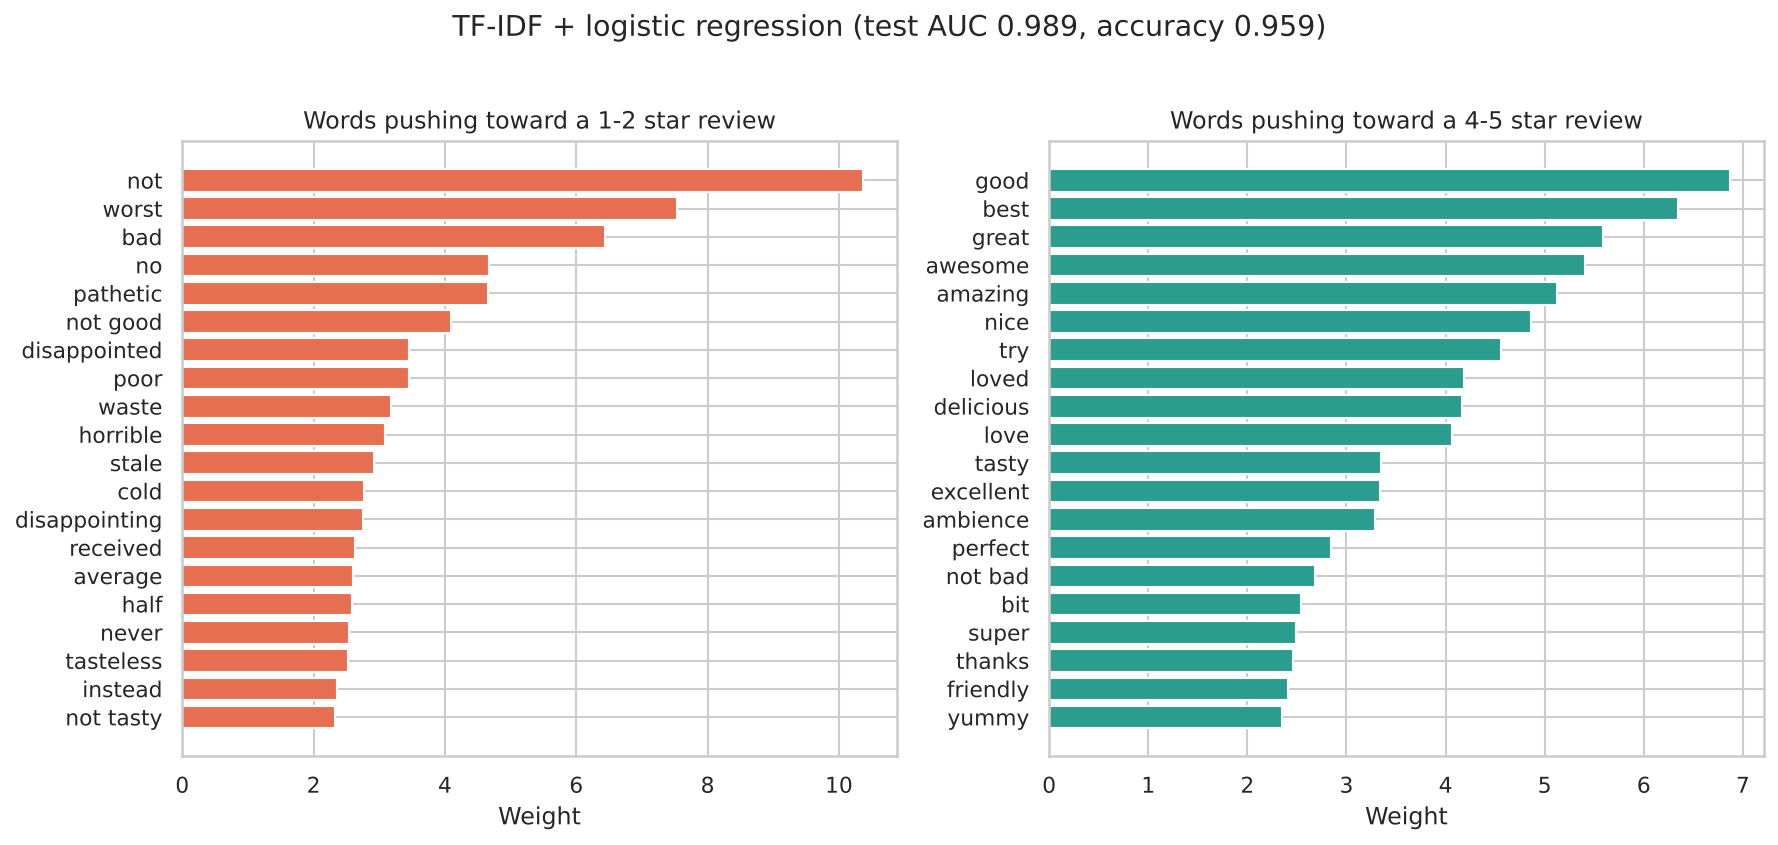

In [15]:
Image("../outputs/figures/06_word_importance.png")

Held-out AUC ≈ 0.99, accuracy ≈ 96%. *Caveat:* this is a vocabulary sanity check, not a production model - star ratings and review text are written by the same person at the same time, so strong agreement is expected.

**Notable negative drivers beyond generic words:** `pathetic`, `disappointed`, `poor`, `waste`, `horrible`, `stale`, `cold`, `tasteless`, `received`, `half` (as in *half cooked*). Most map onto the Food Quality category from notebook 03. On the positive side `not bad` is a useful reminder of why negations must be kept.

## 7. Restaurant "signature" terms (TF-IDF with one document per restaurant)
Each restaurant is treated as one big document; terms common to many restaurants are suppressed (`max_df=0.15`). This surfaces what each place is known for - dishes, staff names, location.

In [16]:
pd.read_csv("../outputs/tables/restaurant_signature_terms.csv").sample(10, random_state=5)

,Restaurant,signature_terms
66,Pakwaan Grand,"pakwaan grand, pakwaan, pakwan, grand, not grilled"
32,Eat India Company,"eat india, urban asia, india company, asia, urban"
46,Jonathan's Kitchen - Holiday Inn Express & Suites,"jonathan, jonathan kitchen, tiger prawns, tiger, sushi"
28,Diners Pavilion,"pavilion, diner pavilion, diners pavilion, greek salad, veg greek"
74,Sardarji's Chaats & More,"bhatoore, bhature, chole bhatoore, chole bhature, chole"
23,Cream Stone,"cream stone, stone, fruit exotica, wonka, willy wonka"
10,Asian Meal Box,"extra egg, egg noodles, sour spicy, spicy curdy, curdy"
20,Chinese Pavilion,"chinese pavilion, pavilion, chinese food, haka, jade"
17,Biryanis And More,"avakai, corn 65, junnu, mango lassi, ginger cola"
35,Flechazo,"sabir, jayanta, ranjit, flechazo, belt"


## 8. Findings
1. ~74% of review text is positive by VADER vs 63% 4-5★: text is more generous than the stars.
2. VADER/stars polarity agreement is ~92%; the disagreements are informative (mixed reviews), not just noise.
3. Complaint categories reveal problems that sentiment hides (Pricing, Staff).
4. A TF-IDF vocabulary alone predicts negative ratings with ~0.99 AUC.
5. n-grams give plain-English phrases for dashboards: `not good`, `worst experience`, `waste money`.
Next: restaurant-level business insights (`05_business_insights.ipynb`).